# Working with Time Series - Statistical Time-Series Analysis

This notebook builds an end-to-end statistical forecasting workflow using daily retail revenue from the **Online Retail II** transaction dataset. The workflow progresses from univariate models (ARIMA and SARIMA) to SARIMAX with lagged exogenous regressors, followed by coefficient inspection and out-of-sample evaluation.

## 1. Imports and Setup

In [26]:
import os
import glob
import zipfile
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.seasonal import seasonal_decompose
from sklearn.metrics import mean_absolute_error, mean_squared_error
import pymc as pm
import arviz as az
# pmdarima is installed below if needed for automatic ARIMA/SARIMA/SARIMAX selection.


g++ not available, if using conda: `conda install gxx`


## 2. Download the Online Retail II Dataset

The dataset is downloaded directly from the UCI repository. No Kaggle account or authentication is required.

In [2]:
url = "https://archive.ics.uci.edu/static/public/502/online+retail+ii.zip"
zip_path = "online_retail_ii.zip"
extract_dir = "online_retail_data"

if not os.path.exists(zip_path):
    urllib.request.urlretrieve(url, zip_path)

if not os.path.exists(extract_dir):
    os.makedirs(extract_dir, exist_ok=True)
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_dir)

files = glob.glob(os.path.join(extract_dir, "*.xlsx"))
print("Files:", files)
print("Downloaded and extracted successfully.")


Files: ['online_retail_data\\online_retail_II.xlsx']
Downloaded and extracted successfully.


## 3. Load and Inspect the Transaction Data

In [3]:
df = pd.read_excel(files[0])

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nFirst five rows:")
display(df.head())


Shape: (525461, 8)
Columns: ['Invoice', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'Price', 'Customer ID', 'Country']

First five rows:


,Invoice,StockCode,Description,Quantity,InvoiceDate,Price,Customer ID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,2009-12-01 07:45:00,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,2009-12-01 07:45:00,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2009-12-01 07:45:00,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,2009-12-01 07:45:00,1.25,13085.0,United Kingdom


## 4. Construct Revenue and Clean the Transactions

Revenue is defined at the transaction-line level as:

**Revenue = Quantity x Price**

For this analysis, non-positive quantities and prices are excluded. This creates a **positive gross-sales series** rather than net revenue including returns/cancellations.

In [4]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
df["Revenue"] = df["Quantity"] * df["Price"]

df_clean = df.loc[
    (df["Quantity"] > 0) &
    (df["Price"] > 0)
].copy()

print("Original rows:", len(df))
print("Clean rows:", len(df_clean))
print("Revenue minimum:", df_clean["Revenue"].min())


Original rows: 525461
Clean rows: 511566
Revenue minimum: 0.001


## 5. Aggregate to a Daily Revenue Time Series

In [5]:
daily_revenue = (
    df_clean
    .assign(Date=df_clean["InvoiceDate"].dt.normalize())
    .groupby("Date", as_index=False)["Revenue"]
    .sum()
    .sort_values("Date")
    .set_index("Date")
)

# Establish a regular daily cadence. Dates with no retained positive-sales
# transactions are represented as zero revenue.
daily_revenue = daily_revenue.asfreq("D", fill_value=0)

print("Start:", daily_revenue.index.min())
print("End:", daily_revenue.index.max())
print("Observations:", len(daily_revenue))
print("Zero-revenue days:", (daily_revenue["Revenue"] == 0).sum())
print("Negative-revenue days:", (daily_revenue["Revenue"] < 0).sum())

display(daily_revenue.head(10))


Start: 2009-12-01 00:00:00
End: 2010-12-09 00:00:00
Observations: 374
Zero-revenue days: 67
Negative-revenue days: 0


,Revenue
Date,
2009-12-01,54513.50
2009-12-02,63352.51
2009-12-03,74037.91
2009-12-04,40732.92
2009-12-05,9803.05
2009-12-06,24613.64
2009-12-07,45083.35
2009-12-08,49517.23
2009-12-09,40616.09


## 6. Visualize Daily Revenue

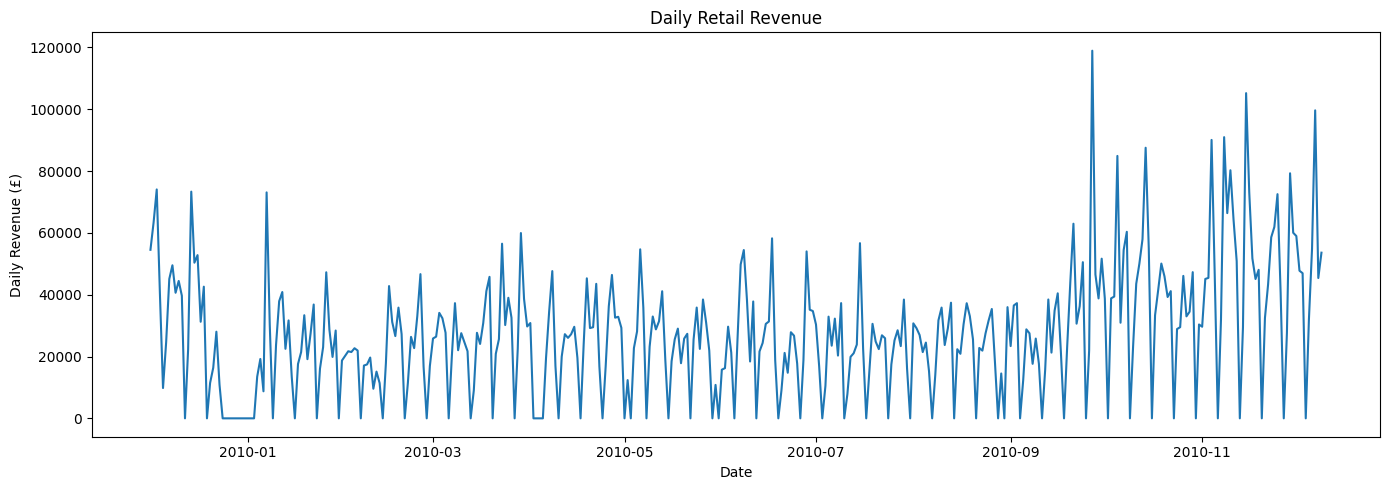

In [6]:
plt.figure(figsize=(14, 5))
plt.plot(daily_revenue.index, daily_revenue["Revenue"])
plt.xlabel("Date")
plt.ylabel("Daily Revenue (£)")
plt.title("Daily Retail Revenue")
plt.tight_layout()
plt.show()


## 7. Seasonal Decomposition

Because the complete regularized daily series contains zero-revenue observations, **additive decomposition** is used as the primary decomposition. A period of 7 represents weekly seasonality for daily data.

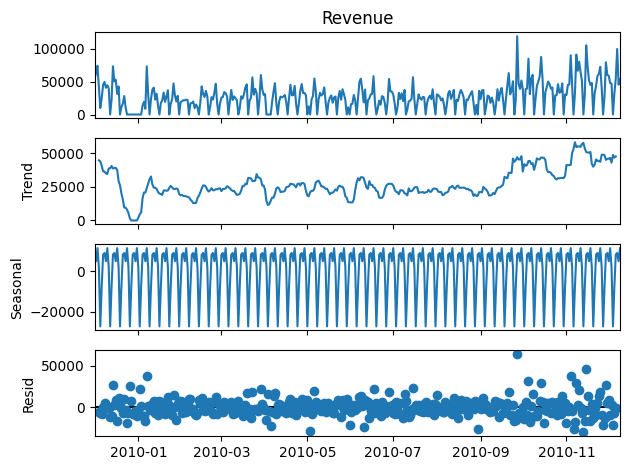

In [7]:
decomp_result = seasonal_decompose(
    daily_revenue["Revenue"],
    model="additive",
    period=7
)

decomp_result.plot()
plt.tight_layout()
plt.show()


### Why additive rather than multiplicative decomposition?

Multiplicative decomposition requires strictly positive observations. This series contains zero-revenue days, so the full daily series cannot be decomposed multiplicatively without changing the data-generating representation. A positive-only multiplicative decomposition can be explored separately, but it is not used as the primary decomposition because removing zero days breaks the regular calendar sequence.

## 8. Install and Import `pmdarima`

In [8]:
%pip install -q pmdarima
from pmdarima import auto_arima



[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


## 9. Time-Based Train/Test Split

A chronological 31-day holdout is used for **all three models** so that the comparison is made on the same future period.

In [9]:
test_days = 31

train = daily_revenue.iloc[:-test_days].copy()
test = daily_revenue.iloc[-test_days:].copy()

y_train = train["Revenue"]
y_test = test["Revenue"]

# Keep the actual dates as the index for all time-series objects.
print("Train period:", train.index.min(), "to", train.index.max())
print("Test period:", test.index.min(), "to", test.index.max())
print("Train observations:", len(train))
print("Test observations:", len(test))
print("Zero values in test:", (y_test == 0).sum())


Train period: 2009-12-01 00:00:00 to 2010-11-08 00:00:00
Test period: 2010-11-09 00:00:00 to 2010-12-09 00:00:00
Train observations: 343
Test observations: 31
Zero values in test: 4


## 10. ARIMA

**ARIMA(p,d,q)** models temporal dependence in the target series using autoregressive terms, differencing, and moving-average error terms. It provides the univariate baseline for the analysis.

In [10]:
arima_model = auto_arima(
    y_train,
    seasonal=False,
    trace=True,
    error_action="ignore",
    suppress_warnings=True,
    stepwise=True
)

print(arima_model.summary())


Performing stepwise search to minimize aic
 ARIMA(2,1,2)(0,0,0)[0] intercept   : AIC=inf, Time=0.28 sec
 ARIMA(0,1,0)(0,0,0)[0] intercept   : AIC=7771.824, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[0] intercept   : AIC=7754.903, Time=0.02 sec
 ARIMA(0,1,1)(0,0,0)[0] intercept   : AIC=7668.796, Time=0.06 sec
 ARIMA(0,1,0)(0,0,0)[0]             : AIC=7769.834, Time=0.01 sec
 ARIMA(1,1,1)(0,0,0)[0] intercept   : AIC=7648.630, Time=0.09 sec
 ARIMA(2,1,1)(0,0,0)[0] intercept   : AIC=7635.533, Time=0.06 sec
 ARIMA(2,1,0)(0,0,0)[0] intercept   : AIC=7709.730, Time=0.03 sec
 ARIMA(3,1,1)(0,0,0)[0] intercept   : AIC=7637.528, Time=0.09 sec
 ARIMA(1,1,2)(0,0,0)[0] intercept   : AIC=7634.230, Time=0.06 sec
 ARIMA(0,1,2)(0,0,0)[0] intercept   : AIC=7633.952, Time=0.04 sec
 ARIMA(0,1,3)(0,0,0)[0] intercept   : AIC=7636.439, Time=0.06 sec
 ARIMA(1,1,3)(0,0,0)[0] intercept   : AIC=7638.566, Time=0.06 sec
 ARIMA(0,1,2)(0,0,0)[0]             : AIC=7629.674, Time=0.04 sec
 ARIMA(0,1,1)(0,0,0)[0]             : 

In [11]:
arima_predictions = np.asarray(
    arima_model.predict(n_periods=len(y_test))
).flatten()

print("ARIMA predictions:")
display(pd.DataFrame({
    "Date": y_test.index,
    "Actual": y_test.values,
    "Predicted": arima_predictions
}).head())


ARIMA predictions:


,Date,Actual,Predicted
0,2010-11-09,66381.06,57676.672236
1,2010-11-10,80244.63,39421.477841
2,2010-11-11,64240.98,39421.477841
3,2010-11-12,50851.12,39421.477841
4,2010-11-13,0.00,39421.477841


## 11. SARIMA

**SARIMA(p,d,q)(P,D,Q)m** extends ARIMA by allowing seasonal autoregressive, differencing, and moving-average terms. For daily data, `m=7` represents a weekly cycle.

In [12]:
sarima_model = auto_arima(
    y_train,
    seasonal=True,
    m=7,
    trace=True,
    error_action="ignore",
    suppress_warnings=True,
    stepwise=True
)

print(sarima_model.summary())


Performing stepwise search to minimize aic
 ARIMA(2,1,2)(1,0,1)[7] intercept   : AIC=inf, Time=0.66 sec
 ARIMA(0,1,0)(0,0,0)[7] intercept   : AIC=7771.824, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[7] intercept   : AIC=7671.491, Time=0.05 sec
 ARIMA(0,1,1)(0,0,1)[7] intercept   : AIC=7608.833, Time=0.29 sec
 ARIMA(0,1,0)(0,0,0)[7]             : AIC=7769.834, Time=0.01 sec
 ARIMA(0,1,1)(0,0,0)[7] intercept   : AIC=7668.796, Time=0.06 sec
 ARIMA(0,1,1)(1,0,1)[7] intercept   : AIC=7544.636, Time=0.39 sec
 ARIMA(0,1,1)(1,0,0)[7] intercept   : AIC=7608.548, Time=0.06 sec
 ARIMA(0,1,1)(2,0,1)[7] intercept   : AIC=7554.619, Time=0.42 sec
 ARIMA(0,1,1)(1,0,2)[7] intercept   : AIC=inf, Time=0.70 sec
 ARIMA(0,1,1)(0,0,2)[7] intercept   : AIC=7619.466, Time=0.19 sec
 ARIMA(0,1,1)(2,0,0)[7] intercept   : AIC=7564.566, Time=0.34 sec
 ARIMA(0,1,1)(2,0,2)[7] intercept   : AIC=inf, Time=0.91 sec
 ARIMA(0,1,0)(1,0,1)[7] intercept   : AIC=inf, Time=0.35 sec
 ARIMA(1,1,1)(1,0,1)[7] intercept   : AIC=7544.309, T

In [13]:
sarima_predictions = np.asarray(
    sarima_model.predict(n_periods=len(y_test))
).flatten()

print("SARIMA predictions:")
display(pd.DataFrame({
    "Date": y_test.index,
    "Actual": y_test.values,
    "Predicted": sarima_predictions
}).head())


SARIMA predictions:


,Date,Actual,Predicted
0,2010-11-09,66381.06,63549.222823
1,2010-11-10,80244.63,51956.005144
2,2010-11-11,64240.98,58706.433541
3,2010-11-12,50851.12,48998.265953
4,2010-11-13,0.00,17491.220162


## 12. Evaluation Metrics

MAPE is not used because the daily series contains zero actual values. Instead, **MAE**, **RMSE**, and **WAPE** are used consistently across ARIMA, SARIMA, and SARIMAX.

$$WAPE = \frac{\sum_t |y_t-\hat{y}_t|}{\sum_t |y_t|}$$

In [14]:
def wape(y_true, y_pred):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denominator = np.sum(np.abs(y_true))
    if denominator == 0:
        return np.nan
    return np.sum(np.abs(y_true - y_pred)) / denominator

def evaluate_forecast(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mse,
        "RMSE": np.sqrt(mse),
        "WAPE": wape(y_true, y_pred)
    }

arima_metrics = evaluate_forecast(y_test, arima_predictions)
sarima_metrics = evaluate_forecast(y_test, sarima_predictions)

metrics_table = pd.DataFrame(
    [arima_metrics, sarima_metrics],
    index=["ARIMA", "SARIMA"]
)

display(metrics_table.style.format({
    "MAE": "£{:,.2f}",
    "MSE": "{:,.2f}",
    "RMSE": "£{:,.2f}",
    "WAPE": "{:.2%}"
}))


,MAE,MSE,RMSE,WAPE
ARIMA,"£21,844.56","753,800,995.47","£27,455.44",44.28%
SARIMA,"£12,800.24","293,760,592.66","£17,139.45",25.95%


## 13. Heuristic Product Categories and Lagged Exogenous Variables

Product descriptions are mapped into approximate product categories using keyword rules. The resulting daily category quantities and operational measures are shifted by one day so that only information available before the forecast target is supplied to SARIMAX.

In [15]:
def assign_product_category(description):
    if pd.isna(description):
        return "Unknown"

    desc = str(description).upper()

    if any(x in desc for x in ["CHRISTMAS", "XMAS", "SANTA", "REINDEER", "SNOWMAN", "NOEL", "HOLLY"]):
        return "Christmas"
    elif any(x in desc for x in ["LIGHT", "LAMP", "LANTERN", "CANDLE", "TEALIGHT", "CANDLEHOLDER"]):
        return "Lighting_Candles"
    elif any(x in desc for x in ["MUG", "CUP", "PLATE", "BOWL", "SPOON", "FORK", "KNIFE", "TEAPOT", "JUG", "GLASS", "BOTTLE", "TRAY", "NAPKIN", "COASTER", "CERAMIC"]):
        return "Kitchen_Dining"
    elif any(x in desc for x in ["FRAME", "CLOCK", "MIRROR", "CUSHION", "DECORATION", "ORNAMENT", "VASE", "WALL", "SIGN", "HOOK"]):
        return "Home_Decor"
    elif any(x in desc for x in ["BAG", "SHOPPER", "PURSE", "HANDBAG", "STORAGE", "BOX", "BASKET"]):
        return "Bags_Storage"
    elif any(x in desc for x in ["NOTEBOOK", "PENCIL", "PEN", "ERASER", "RULER", "STICKER", "CARD", "PAPER", "JOURNAL"]):
        return "Stationery"
    elif any(x in desc for x in ["TOY", "DOLL", "GAME", "PUZZLE", "CHILDREN", "KIDS", "TEDDY"]):
        return "Toys"
    elif any(x in desc for x in ["NECKLACE", "BRACELET", "EARRING", "RING", "BROOCH", "HAIR", "SCARF"]):
        return "Accessories"
    elif any(x in desc for x in ["GARDEN", "PLANT", "FLOWER", "POT", "WATERING"]):
        return "Garden"
    elif any(x in desc for x in ["BATH", "SOAP", "TOWEL"]):
        return "Bathroom"
    else:
        return "Other"

df_clean["Product_Category"] = df_clean["Description"].apply(assign_product_category)
df_clean["Date"] = pd.to_datetime(df_clean["InvoiceDate"]).dt.normalize()
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["Price"]

daily_exog = (
    df_clean
    .groupby("Date")
    .agg(
        Revenue=("Revenue", "sum"),
        Total_Quantity=("Quantity", "sum"),
        Num_Transactions=("Invoice", "nunique"),
        Num_Customers=("Customer ID", "nunique"),
        Num_Products=("StockCode", "nunique"),
        Avg_Price=("Price", "mean"),
        Avg_Quantity=("Quantity", "mean")
    )
    .reset_index()
)

category_features = (
    df_clean
    .pivot_table(
        index="Date",
        columns="Product_Category",
        values="Quantity",
        aggfunc="sum",
        fill_value=0
    )
    .add_prefix("Qty_")
    .reset_index()
)

daily_exog = (
    daily_exog
    .merge(category_features, on="Date", how="left")
    .sort_values("Date")
    .reset_index(drop=True)
)

# Regularize the exogenous table to the same daily calendar as the revenue series.
daily_exog = (
    daily_exog
    .set_index("Date")
    .reindex(daily_revenue.index)
)

# Fill missing category quantities with zero; interpolate continuous measures across
# missing calendar dates so the lagged features remain defined.
category_cols = [c for c in daily_exog.columns if c.startswith("Qty_")]
for col in category_cols:
    daily_exog[col] = daily_exog[col].fillna(0)

continuous_cols = [
    "Total_Quantity", "Num_Transactions", "Num_Customers",
    "Num_Products", "Avg_Price", "Avg_Quantity"
]

daily_exog[continuous_cols] = daily_exog[continuous_cols].interpolate(method="time").ffill().bfill()

# Lag every exogenous variable by one day.
exog_cols = continuous_cols + category_cols
for col in exog_cols:
    daily_exog[f"{col}_Lag1"] = daily_exog[col].shift(1)

lagged_exog_cols = [f"{col}_Lag1" for col in exog_cols]

# Final SARIMAX modeling table: target + lagged predictors.
sarimax_data = pd.DataFrame({"Revenue": daily_revenue["Revenue"]}, index=daily_revenue.index)
sarimax_data = sarimax_data.join(daily_exog[lagged_exog_cols])
sarimax_data = sarimax_data.dropna()

print("SARIMAX dataset shape:", sarimax_data.shape)
print("Number of lagged exogenous variables:", len(lagged_exog_cols))
print("\nLagged variables:")
print(lagged_exog_cols)


SARIMAX dataset shape: (373, 18)
Number of lagged exogenous variables: 17

Lagged variables:
['Total_Quantity_Lag1', 'Num_Transactions_Lag1', 'Num_Customers_Lag1', 'Num_Products_Lag1', 'Avg_Price_Lag1', 'Avg_Quantity_Lag1', 'Qty_Accessories_Lag1', 'Qty_Bags_Storage_Lag1', 'Qty_Bathroom_Lag1', 'Qty_Christmas_Lag1', 'Qty_Garden_Lag1', 'Qty_Home_Decor_Lag1', 'Qty_Kitchen_Dining_Lag1', 'Qty_Lighting_Candles_Lag1', 'Qty_Other_Lag1', 'Qty_Stationery_Lag1', 'Qty_Toys_Lag1']


## 14. SARIMAX Train/Test Data

The SARIMAX model uses the **same final 31-day forecast horizon** as ARIMA and SARIMA. Because one lagged observation is required, the first calendar observation is excluded from the SARIMAX modeling table.

In [16]:
# Use the same final 31 calendar days as the common holdout.
train_sx = sarimax_data.iloc[:-test_days].copy()
test_sx = sarimax_data.iloc[-test_days:].copy()

y_train_sx = train_sx["Revenue"]
y_test_sx = test_sx["Revenue"]

X_train = train_sx.drop(columns=["Revenue"])
X_test = test_sx.drop(columns=["Revenue"])

print("Train:", train_sx.shape)
print("Test :", test_sx.shape)
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("\nTrain dates:", train_sx.index.min(), "to", train_sx.index.max())
print("Test dates :", test_sx.index.min(), "to", test_sx.index.max())


Train: (342, 18)
Test : (31, 18)
X_train: (342, 17)
X_test : (31, 17)

Train dates: 2009-12-02 00:00:00 to 2010-11-08 00:00:00
Test dates : 2010-11-09 00:00:00 to 2010-12-09 00:00:00


## 15. SARIMAX

**SARIMAX** combines ARIMA/SARIMA temporal structure with external regressors. Here, the external variables are lagged by one day to reduce look-ahead bias.

In [17]:
sarimax_model = auto_arima(
    y_train_sx,
    X=X_train,
    seasonal=True,
    m=7,
    trace=True,
    error_action="ignore",
    suppress_warnings=True,
    stepwise=True
)

print(sarimax_model.summary())


Performing stepwise search to minimize aic
 ARIMA(2,0,2)(1,0,1)[7] intercept   : AIC=inf, Time=1.40 sec
 ARIMA(0,0,0)(0,0,0)[7] intercept   : AIC=7585.174, Time=0.14 sec
 ARIMA(1,0,0)(1,0,0)[7] intercept   : AIC=7538.568, Time=1.35 sec
 ARIMA(0,0,1)(0,0,1)[7] intercept   : AIC=7554.415, Time=1.21 sec
 ARIMA(0,0,0)(0,0,0)[7]             : AIC=9237.681, Time=0.02 sec
 ARIMA(1,0,0)(0,0,0)[7] intercept   : AIC=7585.249, Time=0.52 sec
 ARIMA(1,0,0)(2,0,0)[7] intercept   : AIC=7524.194, Time=3.94 sec
 ARIMA(1,0,0)(2,0,1)[7] intercept   : AIC=inf, Time=2.10 sec
 ARIMA(1,0,0)(1,0,1)[7] intercept   : AIC=inf, Time=1.11 sec
 ARIMA(0,0,0)(2,0,0)[7] intercept   : AIC=7522.340, Time=2.56 sec
 ARIMA(0,0,0)(1,0,0)[7] intercept   : AIC=7536.796, Time=0.94 sec
 ARIMA(0,0,0)(2,0,1)[7] intercept   : AIC=7476.077, Time=1.76 sec
 ARIMA(0,0,0)(1,0,1)[7] intercept   : AIC=inf, Time=1.41 sec
 ARIMA(0,0,0)(2,0,2)[7] intercept   : AIC=inf, Time=2.37 sec
 ARIMA(0,0,0)(1,0,2)[7] intercept   : AIC=inf, Time=1.95 s

In [18]:
sarimax_predictions = np.asarray(
    sarimax_model.predict(
        n_periods=len(y_test_sx),
        X=X_test
    )
).flatten()

print("SARIMAX predictions:")
display(pd.DataFrame({
    "Date": y_test_sx.index,
    "Actual": y_test_sx.values,
    "Predicted": sarimax_predictions
}).head())


SARIMAX predictions:


,Date,Actual,Predicted
0,2010-11-09,66381.06,61692.645255
1,2010-11-10,80244.63,53031.107990
2,2010-11-11,64240.98,59206.108101
3,2010-11-12,50851.12,48214.395920
4,2010-11-13,0.00,13643.771686


In [19]:
sarimax_metrics = evaluate_forecast(y_test_sx, sarimax_predictions)

all_metrics = pd.DataFrame(
    [arima_metrics, sarima_metrics, sarimax_metrics],
    index=["ARIMA", "SARIMA", "SARIMAX"]
)

print("Model comparison:")
display(all_metrics.style.format({
    "MAE": "£{:,.2f}",
    "MSE": "{:,.2f}",
    "RMSE": "£{:,.2f}",
    "WAPE": "{:.2%}"
}))


Model comparison:


,MAE,MSE,RMSE,WAPE
ARIMA,"£21,844.56","753,800,995.47","£27,455.44",44.28%
SARIMA,"£12,800.24","293,760,592.66","£17,139.45",25.95%
SARIMAX,"£11,627.41","285,126,722.55","£16,885.70",23.57%


## 16. Regressor Analysis

The fitted SARIMAX model contains both time-series parameters and regression coefficients. The regression component can be inspected through the underlying `statsmodels` results object exposed by `pmdarima` as `arima_res_`.

Coefficient estimates describe **conditional associations within the forecasting model**. They should not be interpreted as causal effects. Because regressors are measured on different scales and several quantity variables are correlated, raw coefficient magnitude is not a standardized measure of variable importance.

In [20]:
results = sarimax_model.arima_res_

param_names = results.param_names
param_values = np.asarray(results.params)
conf_int = np.asarray(results.conf_int())
p_values = np.asarray(results.pvalues)

all_params = pd.DataFrame({
    "Parameter": param_names,
    "Coefficient": param_values,
    "Lower_95_CI": conf_int[:, 0],
    "Upper_95_CI": conf_int[:, 1],
    "P_Value": p_values
})

regressor_results = (
    all_params[all_params["Parameter"].isin(X_train.columns)]
    .copy()
)

regressor_results["Significant_95"] = (
    regressor_results["P_Value"] < 0.05
)

regressor_results["Abs_Coefficient"] = (
    regressor_results["Coefficient"].abs()
)

regressor_results = (
    regressor_results
    .sort_values("Abs_Coefficient", ascending=False)
    .reset_index(drop=True)
)

display(regressor_results[
    [
        "Parameter", "Coefficient", "Lower_95_CI",
        "Upper_95_CI", "P_Value", "Significant_95"
    ]
].style.format({
    "Coefficient": "{:,.4f}",
    "Lower_95_CI": "{:,.4f}",
    "Upper_95_CI": "{:,.4f}",
    "P_Value": "{:.4g}"
}))


,Parameter,Coefficient,Lower_95_CI,Upper_95_CI,P_Value,Significant_95
0,Avg_Price_Lag1,-977.1415,"-2,122.3876",168.1047,0.09447,False
1,Num_Customers_Lag1,588.6452,130.0988,"1,047.1916",0.01187,True
2,Num_Transactions_Lag1,-287.0485,-656.8743,82.7773,0.1282,False
3,Avg_Quantity_Lag1,260.6415,-568.5047,"1,089.7876",0.5378,False
4,Num_Products_Lag1,14.2014,-12.9528,41.3556,0.3053,False
5,Qty_Bathroom_Lag1,-6.4152,-32.1098,19.2794,0.6246,False
6,Qty_Christmas_Lag1,4.2395,1.5723,6.9067,0.001837,True
7,Qty_Lighting_Candles_Lag1,1.9262,-0.9837,4.8362,0.1945,False
8,Qty_Accessories_Lag1,1.7108,-18.7282,22.1497,0.8697,False
9,Qty_Toys_Lag1,1.6213,-10.3756,13.6182,0.7911,False


## 17. Forecast Visualization

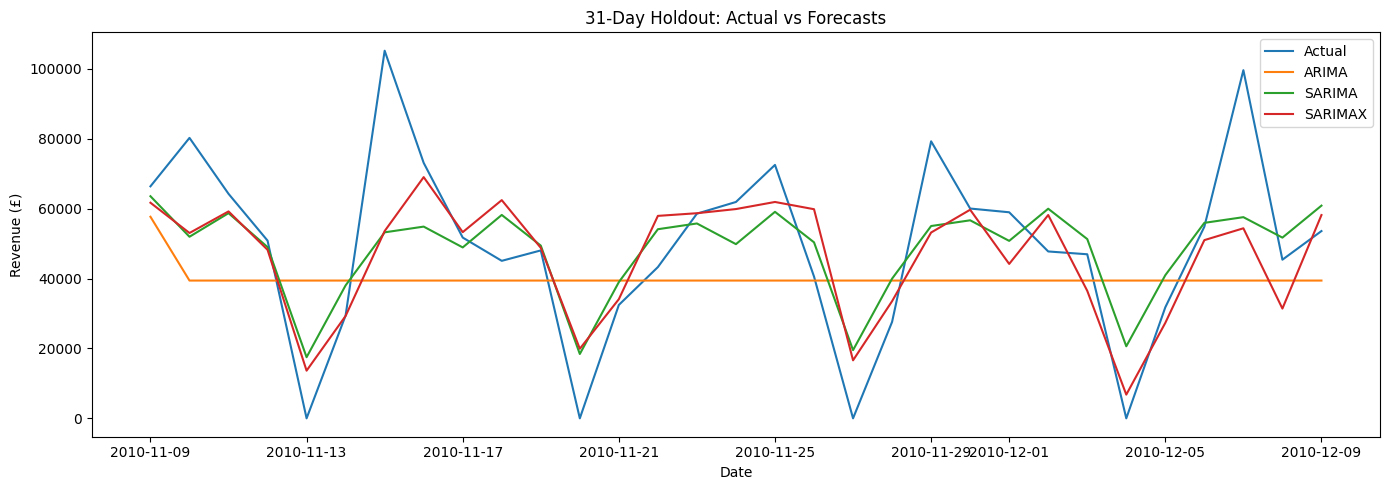

In [21]:
plt.figure(figsize=(14, 5))
plt.plot(y_test.index, y_test.values, label="Actual")
plt.plot(y_test.index, arima_predictions, label="ARIMA")
plt.plot(y_test.index, sarima_predictions, label="SARIMA")
plt.plot(y_test_sx.index, sarimax_predictions, label="SARIMAX")
plt.xlabel("Date")
plt.ylabel("Revenue (£)")
plt.title("31-Day Holdout: Actual vs Forecasts")
plt.legend()
plt.tight_layout()
plt.show()


<h4> Volatility Modeling </h4>

In [ ]:
# ---------------------------------------------------------
# 1. Prepare daily revenue series
# ---------------------------------------------------------
revenue = (
    daily_revenue["Revenue"]
    .sort_index()
    .astype(float)
    .asfreq("D")
)

# Interpolate any missing calendar observations
revenue = revenue.interpolate(method="time")

# Revenue cannot be negative for the cleaned dataset
revenue = revenue.clip(lower=0)

# ---------------------------------------------------------
# 2. Construct log1p daily changes
#
# log1p(x) = log(1+x)
# This remains defined when Revenue = 0.
#
# The resulting change measures day-to-day proportional
# movement on a transformed revenue scale.
# ---------------------------------------------------------
log_revenue = np.log1p(revenue)
log_revenue = np.log1p(revenue)
revenue_change = log_revenue.diff().dropna()

# Align dates
vol_dates = revenue_change.index

print("Revenue observations:", len(revenue))
print("Volatility observations:", len(revenue_change))
print("Mean daily change:", revenue_change.mean())
print("Std daily change:", revenue_change.std())

Revenue observations: 374
Volatility observations: 373
Mean daily change: -4.599694628499797e-05
Std daily change: 5.423276338500113


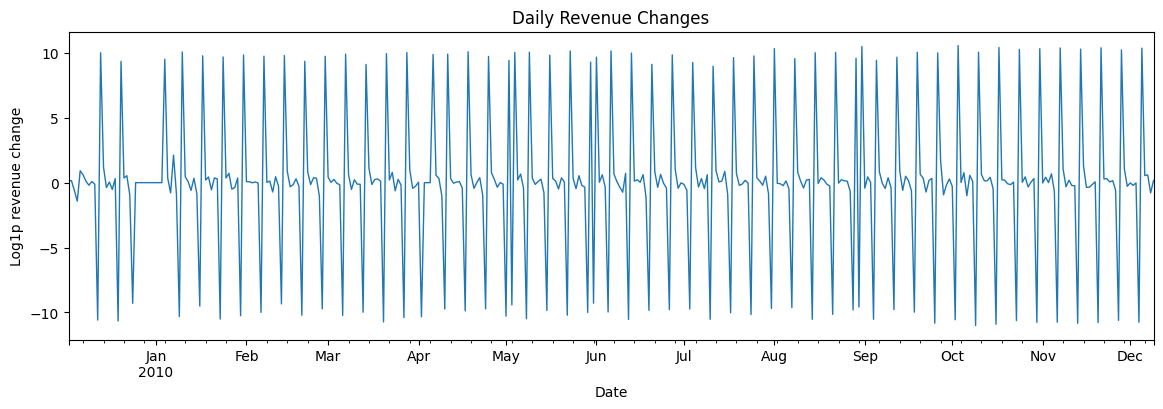

In [31]:
# ---------------------------------------------------------
# 3. Visualize transformed revenue changes
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 4))

revenue_change.plot(
    ax=ax,
    linewidth=1
)

ax.set_xlabel("Date")
ax.set_ylabel("Log1p revenue change")
ax.set_title("Daily Revenue Changes")

plt.show()

In [46]:
# ---------------------------------------------------------
# Stochastic Volatility Model
# ---------------------------------------------------------

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pymc as pm
import arviz as az

# ---------------------------------------------------------
# 1. Prepare regular daily revenue series
# ---------------------------------------------------------
revenue = (
    daily_revenue["Revenue"]
    .sort_index()
    .astype(float)
    .asfreq("D")
)

# Interpolate any missing calendar observations
revenue = revenue.interpolate(method="time")

# Revenue should not be negative
revenue = revenue.clip(lower=0)

# ---------------------------------------------------------
# 2. Transform revenue and compute daily changes
# ---------------------------------------------------------
# log1p handles zero-revenue observations
log_revenue = np.log1p(revenue)

# Daily change on the log1p scale
revenue_change = (
    log_revenue
    .diff()
    .dropna()
)

# Standardize changes for more stable Bayesian sampling
change_mean = revenue_change.mean()
change_sd = revenue_change.std()

standardized_change = (
    (revenue_change - change_mean) /
    change_sd
)

vol_dates = standardized_change.index

coords = {
    "time": vol_dates
}

print("Observations:", len(standardized_change))
print("Mean of transformed changes:", standardized_change.mean())
print("SD of transformed changes:", standardized_change.std())

# ---------------------------------------------------------
# 3. Stochastic volatility model
# ---------------------------------------------------------
with pm.Model(coords=coords) as stochastic_vol_model:

    # Evolution scale of latent log-volatility
    step_size = pm.HalfNormal(
        "step_size",
        sigma=0.15
    )

    # Explicit initial distribution for latent volatility
    init_dist = pm.Normal.dist(
        mu=0.0,
        sigma=0.5
    )

    # Latent time-varying log-volatility
    volatility = pm.GaussianRandomWalk(
        "volatility",
        sigma=step_size,
        init_dist=init_dist,
        dims="time"
    )

    # Student-t degrees of freedom constrained to > 2
    # so the variance remains finite
    nu_minus_two = pm.Exponential(
        "nu_minus_two",
        0.1
    )

    nu = pm.Deterministic(
        "nu",
        nu_minus_two + 2
    )

    # Heavy-tailed observation model
    observed_change = pm.StudentT(
        "observed_change",
        nu=nu,
        mu=0.0,
        sigma=pm.math.exp(volatility),
        observed=standardized_change.values,
        dims="time"
    )

Observations: 373
Mean of transformed changes: 3.6908218513007885e-17
SD of transformed changes: 1.0


In [47]:
# ---------------------------------------------------------
# 6. Prior predictive check
# ---------------------------------------------------------
with stochastic_vol_model:
    prior_predictive = pm.sample_prior_predictive(
        draws=500
    )

# Inspect prior predictive changes
prior_changes = (
    prior_predictive
    .prior_predictive["observed_change"]
)

print(
    "Prior predictive shape:",
    prior_changes.shape
)

Sampling: [nu_minus_two, observed_change, step_size, volatility]


Prior predictive shape: (1, 500, 373)


In [48]:
# ---------------------------------------------------------
# 7. Fit stochastic volatility model
#
# NUTS is used to estimate the latent volatility process.
# ---------------------------------------------------------
with stochastic_vol_model:
    trace = pm.sample(
        draws=2000,
        tune=2000,
        chains=4,
        target_accept=0.9,
        return_inferencedata=True
    )

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [step_size, volatility, nu_minus_two]


c:\Users\bchoud03\AppData\Local\miniconda3\Lib\site-packages\rich\live.py:256: UserWarning: install "ipywidgets" 
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 2_000 tune and 2_000 draw iterations (8_000 + 8_000 draws total) took 17 seconds.


In [49]:
# ---------------------------------------------------------
# 8. Posterior diagnostics
# ---------------------------------------------------------
print(
    az.summary(
        trace,
        var_names=[
            "step_size",
            "nu"
        ],
        round_to=3
    )
)

            mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  \
step_size  1.317  0.070     1.204     1.431  2507.571  3475.441  1.001   
nu         2.138  0.187     2.006     2.423  2783.942  3598.957  1.002   

           mcse_mean  mcse_sd  
step_size      0.001    0.001  
nu             0.004    0.016  


In [50]:
# ---------------------------------------------------------
# 9. Extract posterior latent volatility
#
# volatility is modeled on the log scale.
# exp(volatility) gives the estimated volatility scale.
# ---------------------------------------------------------
posterior = trace.posterior

posterior_volatility = (
    np.exp(
        posterior["volatility"]
    )
)

print(
    "Posterior volatility dimensions:",
    posterior_volatility.dims
)

Posterior volatility dimensions: ('chain', 'draw', 'time')


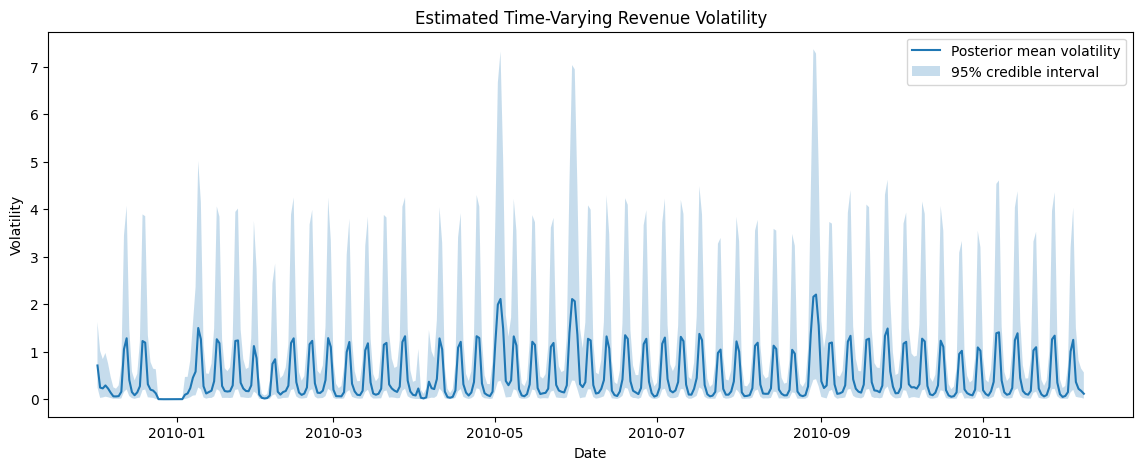

In [51]:
# ---------------------------------------------------------
# 10. Plot estimated volatility over time
# ---------------------------------------------------------
fig, ax = plt.subplots(figsize=(14, 5))

# Posterior mean
vol_mean = (
    posterior_volatility
    .mean(dim=("chain", "draw"))
    .values
)

# Credible interval
vol_lower = (
    posterior_volatility
    .quantile(0.025, dim=("chain", "draw"))
    .values
)

vol_upper = (
    posterior_volatility
    .quantile(0.975, dim=("chain", "draw"))
    .values
)

ax.plot(
    vol_dates,
    vol_mean,
    linewidth=1.5,
    label="Posterior mean volatility"
)

ax.fill_between(
    vol_dates,
    vol_lower,
    vol_upper,
    alpha=0.25,
    label="95% credible interval"
)

ax.set_xlabel("Date")
ax.set_ylabel("Volatility")
ax.set_title("Estimated Time-Varying Revenue Volatility")
ax.legend()

plt.show()

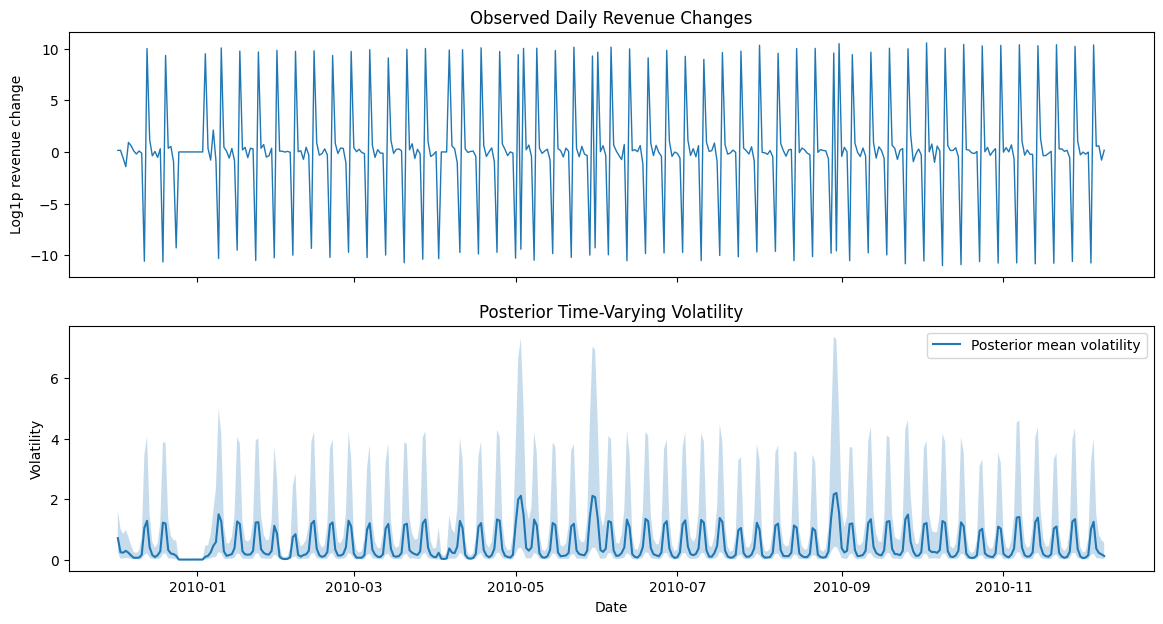

In [52]:
# ---------------------------------------------------------
# 11. Compare revenue changes with estimated volatility
# ---------------------------------------------------------
fig, axes = plt.subplots(
    nrows=2,
    figsize=(14, 7),
    sharex=True
)

# Revenue changes
axes[0].plot(
    vol_dates,
    revenue_change.values,
    linewidth=1
)

axes[0].set_ylabel(
    "Log1p revenue change"
)

axes[0].set_title(
    "Observed Daily Revenue Changes"
)

# Volatility
axes[1].plot(
    vol_dates,
    vol_mean,
    linewidth=1.5,
    label="Posterior mean volatility"
)

axes[1].fill_between(
    vol_dates,
    vol_lower,
    vol_upper,
    alpha=0.25
)

axes[1].set_xlabel("Date")
axes[1].set_ylabel("Volatility")

axes[1].set_title(
    "Posterior Time-Varying Volatility"
)

axes[1].legend()

plt.show()

In [53]:
# ---------------------------------------------------------
# 12. Posterior predictive check
# ---------------------------------------------------------
with stochastic_vol_model:
    posterior_predictive = pm.sample_posterior_predictive(
        trace,
        var_names=["observed_change"],
        random_seed=42
    )

C:\Users\bchoud03\AppData\Local\Temp\ipykernel_37464\3372904970.py:5: ImplicitFreezeWarning: The following trace variables were implicitly frozen, but something in their upstream suggests you may have wanted them resampled: 'volatility' (upstream Data/coords changed (time)). To resample them, pass them in `sample_vars`; to silence this warning while keeping the trace values, pass them in `freeze_vars`.
  posterior_predictive = pm.sample_posterior_predictive(
Sampling: [observed_change]


c:\Users\bchoud03\AppData\Local\miniconda3\Lib\site-packages\rich\live.py:256: UserWarning: install "ipywidgets" 
for Jupyter support
  warnings.warn('install "ipywidgets" for Jupyter support')

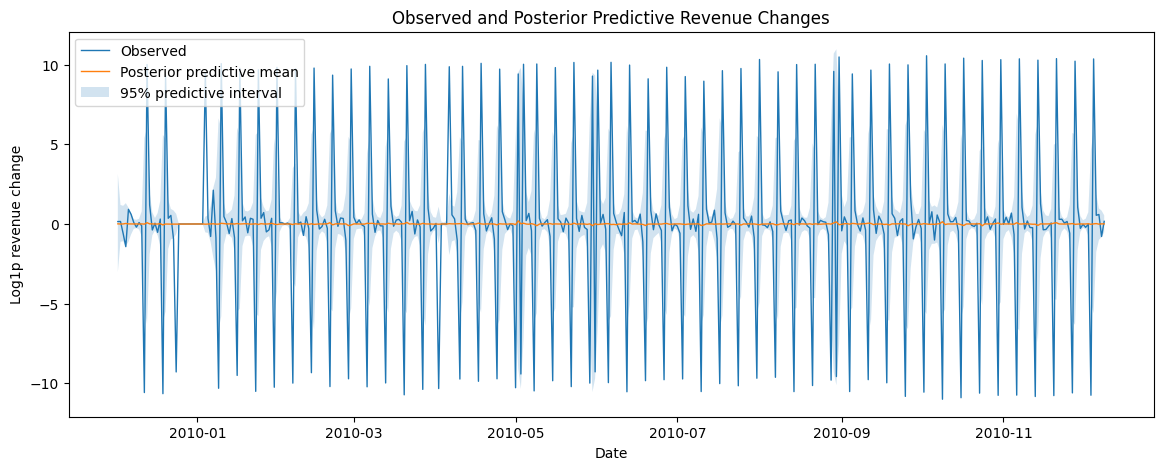

In [54]:
# ---------------------------------------------------------
# 13. Basic posterior predictive visualization
# ---------------------------------------------------------
pp = (
    posterior_predictive
    .posterior_predictive["observed_change"]
)

# Posterior predictive mean
pp_mean = (
    pp.mean(dim=("chain", "draw"))
    .values
)

# Posterior predictive interval
pp_lower = (
    pp.quantile(
        0.025,
        dim=("chain", "draw")
    )
    .values
)

pp_upper = (
    pp.quantile(
        0.975,
        dim=("chain", "draw")
    )
    .values
)

fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(
    vol_dates,
    revenue_change.values,
    linewidth=1,
    label="Observed"
)

ax.plot(
    vol_dates,
    pp_mean,
    linewidth=1,
    label="Posterior predictive mean"
)

ax.fill_between(
    vol_dates,
    pp_lower,
    pp_upper,
    alpha=0.2,
    label="95% predictive interval"
)

ax.set_xlabel("Date")
ax.set_ylabel("Log1p revenue change")
ax.set_title(
    "Observed and Posterior Predictive Revenue Changes"
)

ax.legend()

plt.show()

            mean     sd  eti89_lb  eti89_ub  ess_bulk  ess_tail  r_hat  \
step_size  1.317  0.070     1.204     1.431  2507.571  3475.441  1.001   
nu         2.138  0.187     2.006     2.423  2783.942  3598.957  1.002   

           mcse_mean  mcse_sd  
step_size      0.001    0.001  
nu             0.004    0.016  


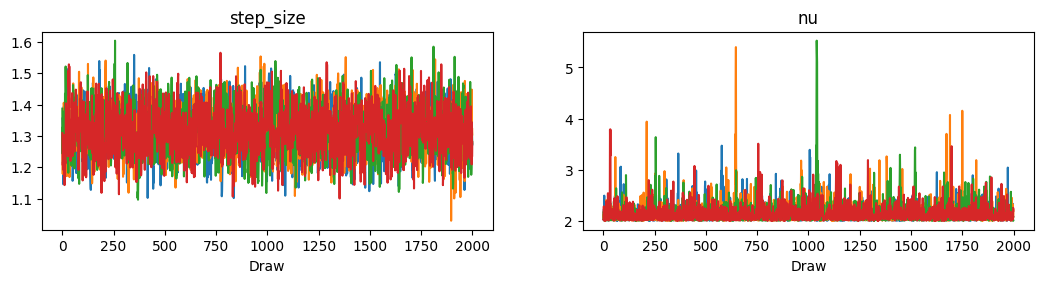

In [55]:
# ---------------------------------------------------------
# 14. Sampling diagnostics
# ---------------------------------------------------------
print(
    az.summary(
        trace,
        var_names=[
            "step_size",
            "nu"
        ],
        round_to=3
    )
)

az.plot_trace(
    trace,
    var_names=[
        "step_size",
        "nu"
    ]
)

plt.show()

## Conclusion

This analysis developed an end-to-end statistical time-series workflow for daily retail revenue, progressing from **ARIMA** to **SARIMA**, **SARIMAX with lagged exogenous regressors**, and finally a Bayesian **stochastic-volatility model**.

Transaction-level retail observations were transformed into a regular daily gross-revenue series using \(Revenue = Quantity \times Price\), with non-positive quantities and prices excluded. The resulting daily series contained zero-revenue days, so **MAE, RMSE, and WAPE** were used for out-of-sample forecast evaluation rather than conventional MAPE.

### Forecasting Results

ARIMA provided the univariate baseline, while SARIMA introduced a weekly seasonal structure with \(m=7\). The selected SARIMA model substantially improved forecast accuracy relative to ARIMA, demonstrating that recurring weekly structure contains useful information for daily retail revenue.

SARIMAX subsequently incorporated **17 one-day-lagged exogenous variables**, including prior-day transaction activity, customer activity, pricing, product diversity, and heuristic product-category quantities. Lagging these predictors preserved temporal ordering and reduced direct look-ahead bias.

On the common **31-day holdout period from 9 November 2010 to 9 December 2010**, the models achieved:

- **ARIMA:** MAE £21,844.56; RMSE £27,455.44; WAPE 44.28%
- **SARIMA:** MAE £12,800.24; RMSE £17,139.45; WAPE 25.95%
- **SARIMAX:** MAE £11,627.41; RMSE £16,885.70; WAPE 23.57%

The results show a substantial reduction in forecast error when weekly seasonality is introduced, followed by a further improvement when lagged operational and product-mix information is incorporated through SARIMAX. Thus, for the evaluated holdout period, the forecasting results support the progression from **historical dependence → seasonal dependence → seasonal dependence plus lagged external information**.

### Exogenous Regressors

The SARIMAX regression component identified statistically supported conditional associations for selected lagged variables. In particular, **prior-day customer count** and **prior-day Christmas-category quantity** had positive coefficient estimates with 95% confidence intervals that excluded zero.

These coefficients describe **conditional associations within the fitted forecasting model**, not causal effects. Their magnitudes should not be compared directly across variables because the regressors have different units and several operational and category variables are correlated by construction.

### Stochastic Volatility

Residual diagnostics from the ARIMA-family models indicated substantial non-normality, heavy tails, and evidence of changing variance. A Bayesian stochastic-volatility model was therefore introduced to model the **time-varying volatility of daily log1p revenue changes**.

Because the daily revenue series contains zero values, the volatility model used a `log1p` transformation before taking daily changes. The transformed changes were standardized prior to Bayesian estimation to improve numerical conditioning. A latent Gaussian random-walk process represented changing log-volatility, while a Student-t observation distribution allowed for heavy-tailed movements.

The final posterior sampling was well behaved. The estimated `step_size` had a posterior mean of approximately **1.317** with \(\hat R=1.001\) and effective sample size above 2,500. The Student-t degrees-of-freedom parameter had a posterior mean of approximately **2.138**, with \(\hat R=1.002\) and effective sample size above 2,700. These diagnostics indicate good posterior mixing and convergence in the executed analysis.

The posterior estimate of \(\nu\) near 2 also supports the presence of **heavy-tailed variation** in the transformed revenue changes. The resulting latent-volatility trajectory provides a complementary view of the series by modeling how variability changes over time rather than modeling only the conditional mean.

The stochastic-volatility model therefore complements SARIMAX rather than replacing it:

**SARIMAX models the expected revenue trajectory using temporal and lagged external information, while stochastic volatility models the changing uncertainty around the transformed revenue process.**

### Overall Findings

The complete workflow can be summarized as:

**ARIMA → SARIMA → SARIMAX → Stochastic Volatility**

where:

- **ARIMA** captures historical dependence.
- **SARIMA** adds weekly seasonal structure.
- **SARIMAX** adds lagged operational and product-mix information.
- **Stochastic volatility** models time-varying variance and heavy-tailed changes.

The forecasting results demonstrate progressively lower holdout error as seasonal and lagged external information are incorporated. The volatility analysis then addresses a complementary feature of the data: the variance of revenue changes is not necessarily constant through time.

### Limitations and Further Development

The forecasting comparison is based on a **single 31-day holdout period**, so the observed performance differences should not be generalized beyond the evaluated period without additional validation. Rolling-origin or expanding-window backtesting would provide a stronger assessment of model stability.

The heuristic product categories are keyword-derived descriptors rather than a validated product taxonomy. In addition, correlated exogenous variables can affect the stability of individual SARIMAX coefficient estimates.

For the Bayesian volatility model, the current posterior sampling diagnostics support interpretation of the fitted posterior, but further model checking could assess whether the stochastic-volatility specification adequately reproduces the observed distribution and clustering of large revenue changes. Posterior predictive diagnostics, alternative volatility priors, and comparison with simpler volatility benchmarks would provide additional validation.

Overall, the notebook demonstrates a coherent progression from **forecasting the conditional mean of daily retail revenue** to **modeling the time-varying uncertainty of the revenue process**, combining classical statistical forecasting with Bayesian volatility modeling.